# Watching a video or giving a rating?

**Before you begin:** Request access to the [Hugging Face dataset](https://huggingface.co/datasets/HABSteam/multimodal-eeg-emotion), then download the preprocessed P001 day-1 emotion-video BDF and its matching `.record_map`. See the [notebook README](README.md) for the access and download commands. Place both files, with their original names, in `sample/PREPROCESSED/P001/`, or change `BDF` below to the downloaded file's path. Keep the sidecar next to the BDF. The notebook also reads `markers.csv`; download it too, into the repository root.

A small, subject-specific EEG decoder: **causal bandpass → CSP log-power → logistic regression**.

1. Read EEG and experiment markers.
2. Learn from the first 70% of complete video/rating cycles; evaluate on the final 30%.
3. Replay the BDF from disk in chunks and predict from a trailing 2 s window.
4. Inspect errors, spatial patterns, compute time, and a live probability display.

**Labels:** rating starts immediately at a video-end marker and ends immediately at the next video-start marker. Instructions and the incomplete final cycle are excluded. Only EEG enters the classifier.

The offline section uses causal filtering too. Here *offline* means batch calculation; *online* means each prediction uses only samples received so far. This makes the comparison fair and keeps one preprocessing recipe.

In [2]:
%matplotlib inline
import sys
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd
from IPython.display import display
from mne.decoding import CSP
from scipy.signal import butter, sosfilt, sosfilt_zi
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    accuracy_score,
    balanced_accuracy_score,
    roc_auc_score,
)
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# VS Code may start the kernel in the repository or in scripts/.
cwd = Path.cwd().resolve()
if (cwd / "starting_notebooks" / "bdf_loader.py").is_file():
    ROOT = cwd
elif cwd.name == "starting_notebooks" and (cwd / "bdf_loader.py").is_file():
    ROOT = cwd.parent
else:
    raise RuntimeError("Start the kernel in the repository root or starting_notebooks/.")

from bdf_loader import load_bdf

# Keep the notebook output focused on results.
mne.set_log_level("ERROR")

## Load EEG and markers

The shared `load_bdf` function reads the recording and its channel metadata without BrainOsTools.

In [4]:
BDF = ROOT / "sample/PREPROCESSED/P001/P001_day-1_task-emotion-video_multimodal.bdf"
raw, data_df, channels = load_bdf(BDF)
fs = float(raw.info["sfreq"])
eeg_rows = channels[channels["mne_type"] == "eeg"]
ch_names = eeg_rows["bdf_label"].tolist()
print(f"{len(ch_names)} EEG channels, {fs:g} samples per second")
print(f"Recording length: {len(data_df) / fs:.1f} seconds")

Channel metadata: P001_day-1_task-emotion-video_multimodal.record_map
Gaze: stored 166 Hz, effective 166.358 Hz, onset 0.001 s
62 EEG channels, 1000 samples per second
Recording length: 856.8 seconds


The signal table uses the units in the BDF header. This recording stores EEG in microvolts; convert it to volts for MNE. The loader removes the final file padding using the record map.

In [5]:
assert set(eeg_rows["header_unit"]) == {"uV"}, "Check EEG units before converting to volts."
eeg_v = data_df[ch_names].to_numpy().T * 1e-6
del data_df
print(f"EEG shape: {eeg_v.shape} (channels × samples), in volts")

EEG shape: (62, 856808) (channels × samples), in volts


Extract the event codes and their times. These are used to make labels; the decoder itself receives only EEG.

In [6]:
annotations = raw.annotations
events = pd.DataFrame({
    "time": annotations.onset - raw.first_time,
    "code": annotations.description.astype(int),
})
raw.close()
events.head()

,time,code
0,0.000,10212
1,10.252,10213
2,74.381,11112
3,84.643,11113
4,102.017,10812


## 2 · Label video and rating periods

The CSV maps video start codes to their matching end codes. Pair consecutive events and look up the video name. The check catches a missing or mismatched marker before it can create incorrect labels.

In [8]:
marker_key = pd.read_csv(ROOT / "markers.csv").set_index("Start Marker")
video_rows = []
for i in range(0, len(events), 2):
    start, end = events.iloc[i], events.iloc[i + 1]
    assert end.code == marker_key.loc[start.code, "End Marker"] and end.time > start.time
    video_rows.append((start.time, end.time, marker_key.loc[start.code, "Emotion or task"]))
videos = pd.DataFrame(video_rows, columns=["start", "end", "emotion"])
print(f"{len(videos)} videos")
videos.head()

36 videos


,start,end,emotion
0,0.000,10.252,Fear
1,74.381,84.643,Curiosity
2,102.017,112.276,Relaxation
3,123.534,131.464,Relaxation
4,147.967,158.223,Curiosity


A rating begins when a video ends and ends when the next video starts. Each complete **cycle** contains one video followed by its rating. The last video has no recorded end for its following rating, so we leave that incomplete cycle out.

In [9]:
cycles = videos.iloc[:-1].copy()
cycles["rating_end"] = videos.start.iloc[1:].to_numpy()
print(f"{len(cycles)} complete video/rating cycles")
cycles.head() 

35 complete video/rating cycles


,start,end,emotion,rating_end
0,0.000,10.252,Fear,74.381
1,74.381,84.643,Curiosity,102.017
2,102.017,112.276,Relaxation,123.534
3,123.534,131.464,Relaxation,147.967
4,147.967,158.223,Curiosity,180.316


Use the first 70% of cycles to train and the remaining later cycles to test. Whole cycles stay together; no windows from the test period enter training.

In [10]:
train_fraction = 0.70
n_train_cycles = int(train_fraction * len(cycles))
cut_s = float(cycles.start.iloc[n_train_cycles])
end_s = float(cycles.rating_end.iloc[-1])
print(f"Training: {n_train_cycles} cycles; test: {len(cycles) - n_train_cycles} cycles")
print(f"Test starts at {cut_s:.1f} s and ends at {end_s:.1f} s")

Training: 24 cycles; test: 11 cycles
Test starts at 629.1 s and ends at 848.6 s


Create one row per period. Label **0** means rating and **1** means watching.

In [11]:
intervals = []
for cycle, row in cycles.iterrows():
    intervals += [(row.start, row.end, 1, cycle),
                  (row.end, row.rating_end, 0, cycle)]
intervals = pd.DataFrame(intervals, columns=["start", "end", "label", "cycle"])
intervals["split"] = np.where(intervals.cycle < n_train_cycles, "train", "test")
intervals

,start,end,label,cycle,split
0,0.000,10.252,1,0,train
1,10.252,74.381,0,0,train
2,74.381,84.643,1,1,train
3,84.643,102.017,0,1,train
4,102.017,112.276,1,2,train
...,...,...,...,...,...
65,802.817,813.349,0,32,test
66,813.349,823.607,1,33,test
67,823.607,832.147,0,33,test
68,832.147,842.294,1,34,test


The timeline shows the two states and where the held-out test begins.

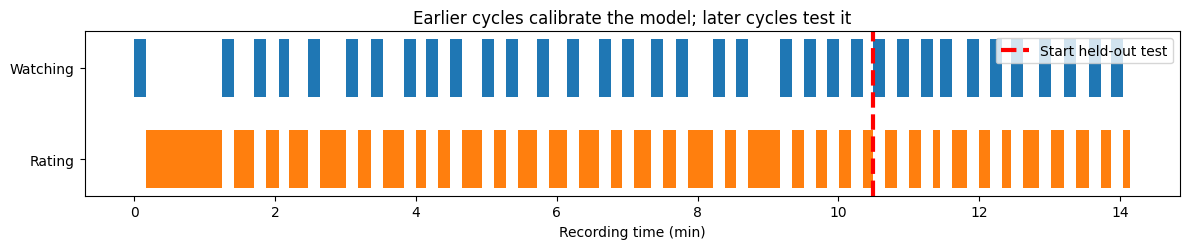

In [12]:
CLASS_NAMES = ["Rating", "Watching"]  # Label 0 is rating; label 1 is watching.
COLORS = plt.rcParams["axes.prop_cycle"].by_key()["color"][:2][::-1]

fig, ax = plt.subplots(figsize=(12, 2.6))
for row in intervals.itertuples():
    ax.broken_barh([(row.start / 60, (row.end-row.start) / 60)],
                   (row.label-.32, .64), facecolors=COLORS[row.label])
ax.axvline(cut_s / 60, color="r", ls="--", lw=3, label="Start held-out test")
ax.set(yticks=[0, 1], yticklabels=CLASS_NAMES, xlabel="Recording time (min)",
       title="Earlier cycles calibrate the model; later cycles test it")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show();

## 3 · Create labeled windows

A training or evaluation window is 2 seconds long. We exclude windows within 1 second of a transition, so each label refers to a single state. Continuous replay later also predicts through transitions.

In [13]:
# Average power over 2 s windows; discard 1 s next to state changes.
WINDOW_S = 2.0
GUARD_S = 1.0
# The recording is 1000 Hz. Decimate by 4 after bandpass filtering.
DECIM = 4
assert fs == 1000  # Update DECIM and the sample-rate assumption for other recordings.
model_fs = fs / DECIM

Assign each window a state and a cycle number. The cycle number keeps neighboring windows together during validation.

In [14]:
def label_windows(starts_s, ends_s, guard=GUARD_S):
    labels = np.full(len(starts_s), -1, dtype=int)
    groups = np.full(len(starts_s), -1, dtype=int)
    for row in intervals.itertuples():
        inside = (starts_s >= row.start + guard) & (ends_s <= row.end - guard)
        labels[inside], groups[inside] = row.label, row.cycle
    return labels, groups

win_n = int(WINDOW_S * model_fs)
starts = np.arange(0, int(end_s * model_fs) - win_n + 1, win_n)
y, groups = label_windows(starts / model_fs, (starts + win_n) / model_fs)
valid = y >= 0
starts, y, groups = starts[valid], y[valid], groups[valid]
train = groups < n_train_cycles
test = ~train
print(pd.crosstab(np.where(train, "train", "test"),
                  np.array(CLASS_NAMES)[y], rownames=["split"]))

col_0  Rating  Watching
split                  
test       29        36
train     147        72


Average-reference each sample, then apply a **forward** bandpass filter. The filter is followed by downsampling from 1000 to 250 Hz. `epoch_array` gathers the filtered windows.

In [15]:
def filter_batch(data, band):
    sos = butter(4, band, btype="bandpass", fs=fs, output="sos")
    zi = sosfilt_zi(sos)[:, None, :] * data[None, :, 0, None]
    filtered, _ = sosfilt(sos, data, zi=zi, axis=-1)
    return filtered[:, ::DECIM]  # Low-pass first, then retain every fourth sample.

def epoch_array(filtered, sample_starts):
    return np.stack([filtered[:, s:s + win_n] for s in sample_starts])

The classifier has three steps: CSP creates spatial power features, scaling puts them on comparable scales, and logistic regression estimates the probability of watching.

In [16]:
info = mne.create_info(ch_names, model_fs, "eeg")
info.set_montage("standard_1020")

def make_decoder(k):
    return make_pipeline(
        CSP(n_components=k, reg=0.1, log=True, info=info,
            rank={"eeg": len(ch_names)-1}),
        StandardScaler(),
        LogisticRegression(C=1, class_weight="balanced", max_iter=1000))

## 4 · Choose settings on training data

We compare frequency bands and CSP sizes using chronological validation **within the earlier training cycles**. Each fold refits CSP and the classifier. Balanced accuracy is the average recall of the two classes; chance is 0.5.

In [17]:
folds = []
for earlier, later in TimeSeriesSplit(n_splits=3).split(np.arange(n_train_cycles)):
    folds.append((np.flatnonzero(np.isin(groups[train], earlier)),
                  np.flatnonzero(np.isin(groups[train], later))))

Fit each candidate on earlier cycles and score it on later training cycles. Freeze the best settings before touching the held-out test.

In [18]:
# Average reference uses only the current sample, so it is causal.
referenced = eeg_v - eeg_v.mean(axis=0, keepdims=True)

selection = []
for band in [(4, 30), (4, 8), (8, 12)]:  # testing narrow bands (theta, alpha) as well as broad ranges (4-30)
    calibration = filter_batch(referenced[:, :round(cut_s * fs)], band)
    X_cal = epoch_array(calibration, starts[train])
    for k in [4, 8, 12]:
        fold_scores = []
        for fit_idx, val_idx in folds:
            candidate = make_decoder(k).fit(X_cal[fit_idx], y[train][fit_idx])
            fold_scores.append(balanced_accuracy_score(
                y[train][val_idx], candidate.predict(X_cal[val_idx])))
        selection.append({"band": band, "components": k,
                          "validation_BA": np.mean(fold_scores), "folds": fold_scores})
selection = pd.DataFrame(selection).sort_values("validation_BA", ascending=False)
best = selection.iloc[0]
BAND, N_COMPONENTS = tuple(best.band), int(best.components)
print("Frozen settings:", BAND, "Hz,", N_COMPONENTS, "CSP components")
del calibration, X_cal, candidate
selection

Frozen settings: (8, 12) Hz, 4 CSP components


,band,components,validation_BA,folds
6,"(8, 12)",4,0.865252,"[0.8304597701149425, 0.9242424242424243, 0.841..."
7,"(8, 12)",8,0.841537,"[0.8199233716475096, 0.8636363636363636, 0.841..."
8,"(8, 12)",12,0.836684,"[0.7710727969348659, 0.9242424242424243, 0.814..."
1,"(4, 30)",8,0.806355,"[0.6226053639846744, 0.9090909090909092, 0.887..."
0,"(4, 30)",4,0.798997,"[0.7097701149425287, 0.8535353535353536, 0.833..."
2,"(4, 30)",12,0.773923,"[0.5804597701149425, 0.8939393939393939, 0.847..."
5,"(4, 8)",12,0.741371,"[0.646551724137931, 0.7954545454545454, 0.7821..."
3,"(4, 8)",4,0.738418,"[0.6015325670498084, 0.9116161616161615, 0.702..."
4,"(4, 8)",8,0.725445,"[0.6187739463601533, 0.7954545454545454, 0.762..."


## 5 · Fit and evaluate offline

Filter the complete array in one batch. The filter is causal, so future samples do not influence the training part. Fit once on training windows, then predict the later test windows.

In [19]:
filtered = filter_batch(referenced, BAND)
X_train = epoch_array(filtered, starts[train])
X_test = epoch_array(filtered, starts[test])
decoder = make_decoder(N_COMPONENTS)
decoder.fit(X_train, y[train])
p_offline = decoder.predict_proba(X_test)[:, 1]

These helpers calculate accuracy, balanced accuracy, ROC AUC, and an uncertainty interval by resampling whole test cycles.

In [20]:
def metrics(truth, probability):
    pred = (probability >= .5).astype(int)
    return {"accuracy": accuracy_score(truth, pred),
            "balanced_accuracy": balanced_accuracy_score(truth, pred),
            "ROC_AUC": roc_auc_score(truth, probability)}

Print held-out scores. The interval describes variation across these cycles for this subject and session.

In [21]:
print("Offline held-out:", metrics(y[test], p_offline))

Offline held-out: {'accuracy': 0.8923076923076924, 'balanced_accuracy': 0.8960727969348659, 'ROC_AUC': 0.9492337164750957}


The confusion matrix shows the kinds of errors; the ROC curve summarizes discrimination over different thresholds.

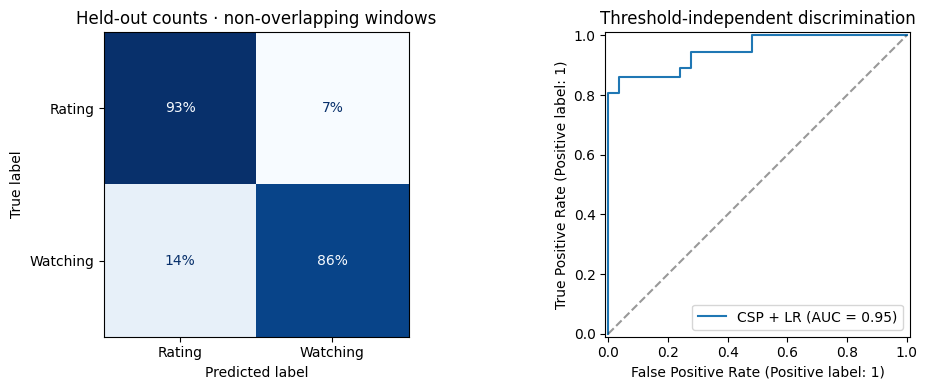

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(y[test], p_offline >= .5,
    display_labels=CLASS_NAMES, ax=axes[0], colorbar=False, cmap="Blues", normalize="true", values_format=".0%")
axes[0].set_title("Held-out counts · non-overlapping windows")
RocCurveDisplay.from_predictions(y[test], p_offline, ax=axes[1], name="CSP + LR")
axes[1].plot([0, 1], [0, 1], "k--", alpha=.4)
axes[1].set_title("Threshold-independent discrimination")
plt.tight_layout(); plt.show()

## 6 · Inspect the learned signal

CSP patterns show how a component projects onto sensors. We show the four components with the largest absolute logistic-regression weights. Their signs are arbitrary and they are not a ranking of individual channels. Frontal or peripheral patterns may also reflect eye or muscle activity.

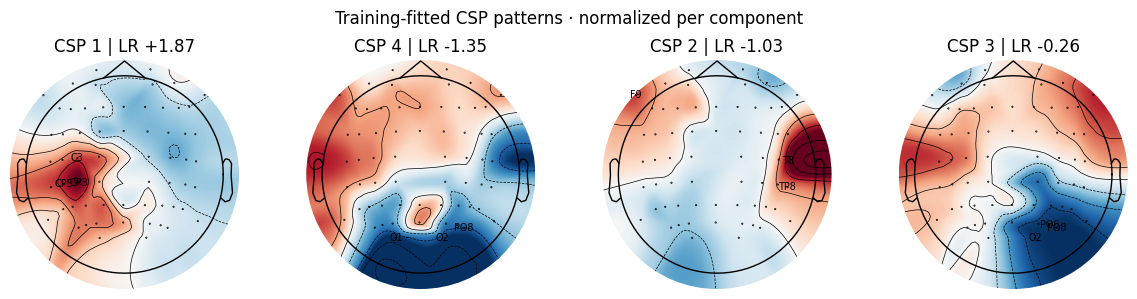

,component,largest pattern magnitudes
0,1,"CP3, CP5, C3"
1,4,"O1, O2, PO8"
2,2,"T8, F9, TP8"
3,3,"PO8, O2, PO6"


In [23]:
top_k = 4

csp = decoder.named_steps["csp"]
weights = decoder.named_steps["logisticregression"].coef_[0]
important = np.argsort(np.abs(weights))[-top_k:][::-1]
fig, axes = plt.subplots(1, 4, figsize=(12, 3))
pattern_rows = []
for ax, component in zip(axes, important):
    pattern = csp.patterns_[component]
    norm = pattern / np.max(np.abs(pattern))
    largest = np.argsort(np.abs(pattern))[-3:][::-1]
    names = [name if j in largest else "" for j, name in enumerate(ch_names)]
    mne.viz.plot_topomap(norm, info, axes=ax, show=False, cmap="RdBu_r",
                        vlim=(-1, 1), names=names)
    ax.set_title(f"CSP {component + 1} | LR {weights[component]:+.2f}")
    pattern_rows.append({"component": component + 1,
        "largest pattern magnitudes": ", ".join(ch_names[j] for j in largest)})
fig.suptitle("Training-fitted CSP patterns · normalized per component")
plt.tight_layout(); plt.show()
pd.DataFrame(pattern_rows)

## 7 · Replay the test EEG online

Read the original BDF in chunks of `HOP_S` seconds. Keep the filter state between chunks and hold only the latest 2 seconds for each prediction. Filtering and prediction use present and past samples. The model stays frozen.

First calculate the filter state accumulated during calibration; the replay begins from this saved state.

In [24]:
import asyncio

# Receive a new chunk every HOP_S seconds.
HOP_S = .2
chunk_samples = round(HOP_S * fs)

# Create the bandpass filter.
sos = butter(4, BAND, btype="bandpass", fs=fs, output="sos")

# Start replay at the last chunk boundary before the test period.
replay_start = int(cut_s * fs)
replay_start = (replay_start // chunk_samples) * chunk_samples

# Use only the EEG recorded before that boundary.
calibration_data = referenced[:, :replay_start]

# Initialize one filter state for each EEG channel.
first_sample = calibration_data[:, 0]
initial_state = sosfilt_zi(sos)[:, None, :] * first_sample[None, :, None]

# Filter the calibration data and keep the state at the end.
filtered_calibration, calibration_zi = sosfilt(
    sos, calibration_data, zi=initial_state, axis=-1
)

# Downsample and keep the most recent 2 seconds for the first prediction.
downsampled = filtered_calibration[:, ::DECIM]
calibration_buffer = downsampled[:, -win_n:].copy()

`replay()` processes one chunk at a time, predicts using the latest window, and records processing times. `speed=0` replays as fast as possible; `speed=1` follows the recording clock for the live display.

In [25]:
async def replay(stop_s=end_s, speed=0, update=None):
    raw = mne.io.read_raw_bdf(BDF, include=ch_names, preload=False, verbose=False)
    assert raw.ch_names == ch_names and raw.info["sfreq"] == fs
    zi, buffer = calibration_zi.copy(), calibration_buffer.copy()
    rows, clock_start = [], perf_counter()
    limit = min(round(stop_s * fs), eeg_v.shape[1])
    try:
        for start in range(replay_start, limit - chunk_samples + 1, chunk_samples):
            end = start + chunk_samples
            t_end = end / fs
            # Read arrival-sized chunks; pacing is separate from compute timing.
            if t_end >= cut_s and speed > 0:
                due = clock_start + (t_end - cut_s) / speed
                await asyncio.sleep(max(0, due - perf_counter()))
            t0 = perf_counter()
            chunk = raw.get_data(start=start, stop=end)
            t1 = perf_counter()
            chunk -= chunk.mean(axis=0, keepdims=True)
            chunk, zi = sosfilt(sos, chunk, zi=zi, axis=-1)
            buffer = np.concatenate([buffer, chunk[:, ::DECIM]], axis=1)[:, -win_n:]
            t2 = perf_counter()
            if t_end >= cut_s and buffer.shape[1] == win_n:
                probability = decoder.predict_proba(buffer[None])[0, 1]
                t3 = perf_counter()
                rows.append((t_end, probability, (t1-t0)*1000,
                             (t2-t1)*1000, (t3-t2)*1000, (t3-t0)*1000))
                if update is not None:
                    update(t_end, probability)
                if speed == 0 and len(rows) % 500 == 0:
                    print(f"Replayed {t_end-cut_s:.0f} s of held-out EEG")
                if len(rows) % 25 == 0:
                    await asyncio.sleep(0.001)  # Let Jupyter process UI events.
    finally:
        raw.close()
    return pd.DataFrame(rows, columns=["time", "p_watch", "read_ms", "filter_ms",
                                        "predict_ms", "total_ms"])

Run the complete held-out replay. Add labels only afterwards, for evaluation.

In [26]:
online = await replay()
# Labels are attached AFTER the replay; they never enter predict_proba().
online["label"], online["cycle"] = label_windows(
    online.time.to_numpy() - WINDOW_S, online.time.to_numpy())
online["clean"] = (online.label >= 0) & (online.cycle >= n_train_cycles)
clean = online[online.clean].copy()

Replayed 100 s of held-out EEG
Replayed 200 s of held-out EEG


Compare online and offline predictions for the same non-overlapping windows. Then score the online updates. The equality check catches a preprocessing mismatch.

In [27]:
# Compare the offline and online predictions at their shared window endpoints.
end_times = np.round((starts[test] + win_n) / model_fs, 6)
online_by_time = online.set_index(online.time.round(6))
shared = np.isin(end_times, online_by_time.index)
if not shared.any():
    raise ValueError("No matching window endpoints; check the replay step and start time.")
matched = online_by_time.loc[end_times[shared]]
max_difference = np.max(np.abs(matched.p_watch.to_numpy() - p_offline[shared]))
assert max_difference < 1e-6, "Disk replay and batch predictions disagree"
print(f"Compared {shared.sum()} matching windows; maximum probability difference: {max_difference:.2g}")
results = pd.DataFrame({
    "Offline · 2 s step": metrics(y[test], p_offline),
    "Online · matching 2 s windows": metrics(y[test][shared], matched.p_watch.to_numpy()),
    f"Online · {HOP_S:g} s step, clean windows": metrics(clean.label, clean.p_watch),
}).T
results

Compared 65 matching windows; maximum probability difference: 4e-14


,accuracy,balanced_accuracy,ROC_AUC
Offline · 2 s step,0.892308,0.896073,0.949234
Online · matching 2 s windows,0.892308,0.896073,0.949234
"Online · 0.2 s step, clean windows",0.878419,0.880502,0.944502


## 8 · Inspect online predictions

The current-state score includes transition windows, when the 2-second history may contain both states. Orange indicates rating and blue indicates watching. Overlapping updates are correlated.

In [28]:
current, current_cycle = label_windows(online.time.to_numpy() - 1e-6,
                                         online.time.to_numpy(), guard=0)
current_valid = (current >= 0) & (current_cycle >= n_train_cycles)
current_metrics = metrics(current[current_valid], online.p_watch.to_numpy()[current_valid])
print("Current-state score including transitions:", current_metrics)
results.loc["Online · current state, transitions included"] = current_metrics

Current-state score including transitions: {'accuracy': 0.7522768670309654, 'balanced_accuracy': 0.7535008052599246, 'ROC_AUC': 0.7857244848826976}


Follow the predicted probability over time and compare balanced accuracy across held-out cycles.

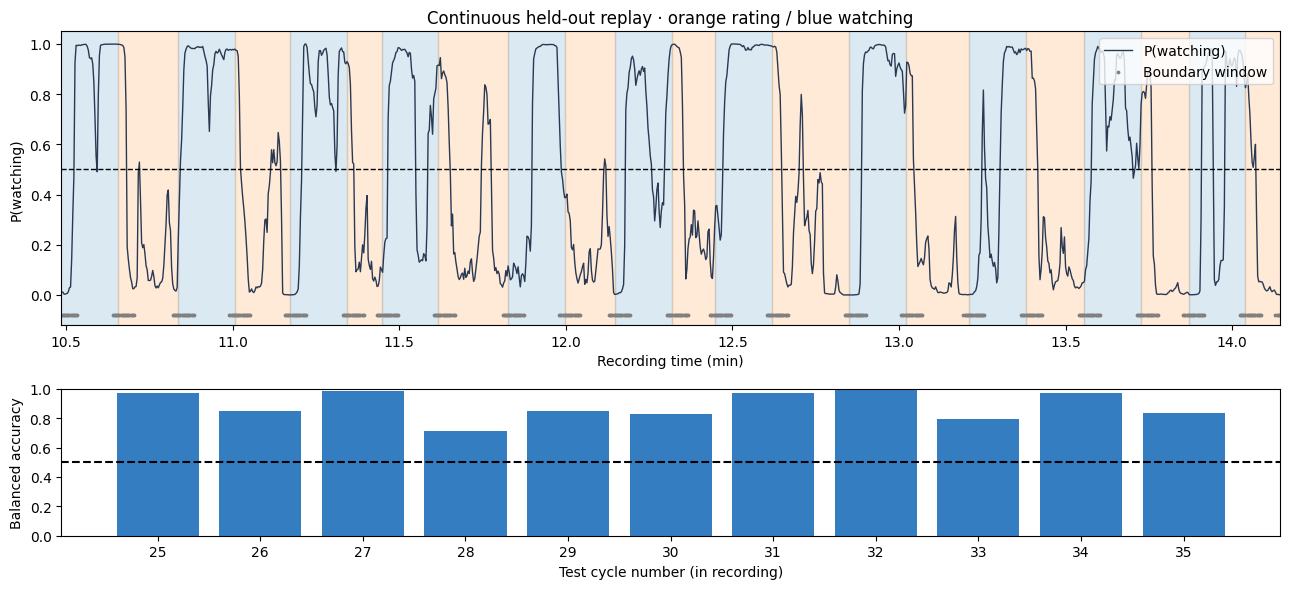

In [29]:
fig, axes = plt.subplots(2, 1, figsize=(13, 6), gridspec_kw={"height_ratios": [2, 1]})
for row in intervals[intervals.split == "test"].itertuples():
    axes[0].axvspan(row.start/60, row.end/60, color=COLORS[row.label], alpha=.16)
axes[0].plot(online.time/60, online.p_watch, color="#293952", lw=1, label="P(watching)")
axes[0].scatter(online.loc[~online.clean, "time"]/60,
                np.full((~online.clean).sum(), -.08), c="gray", s=3, label="Boundary window")
axes[0].axhline(.5, color="black", ls="--", lw=1)
axes[0].set(xlim=(cut_s/60, end_s/60), ylim=(-.12, 1.05),
            xlabel="Recording time (min)", ylabel="P(watching)",
            title="Continuous held-out replay · orange rating / blue watching")
axes[0].legend(loc="upper right")
by_cycle = clean.groupby("cycle").apply(
    lambda g: balanced_accuracy_score(g.label, g.p_watch >= .5), include_groups=False)
axes[1].bar(by_cycle.index + 1, by_cycle, color="#347dc1")
axes[1].axhline(.5, color="black", ls="--")
axes[1].set(xlabel="Test cycle number (in recording)", ylabel="Balanced accuracy",
            ylim=(0, 1), xticks=by_cycle.index + 1)
plt.tight_layout(); plt.show()

## 9 · Measure latency

The history and update intervals determine how quickly new evidence enters a decision. CPU time is separate: the table includes disk reading, filtering, and prediction, but excludes display and hardware acquisition.

In [30]:
timing = online[["read_ms", "filter_ms", "predict_ms", "total_ms"]].quantile([.5, .95, .99]).T
timing.columns = ["median_ms", "p95_ms", "p99_ms"]
display(timing)
print(f"Chunks exceeding the {HOP_S*1000:.0f} ms compute budget:",
      int((online.total_ms > HOP_S*1000).sum()), "of", len(online))
print(f"History: {WINDOW_S:g} s; prediction every {HOP_S:g} s")


,median_ms,p95_ms,p99_ms
read_ms,3.47260,5.243520,6.321863
filter_ms,0.20380,0.343315,0.424925
predict_ms,0.58815,1.134275,1.426602
total_ms,4.35470,6.338730,7.354145


Chunks exceeding the 200 ms compute budget: 0 of 1098
History: 2 s; prediction every 0.2 s


A causal IIR filter has frequency-dependent group delay. This plot describes narrowband envelope delay; it is not a single fixed prediction delay.

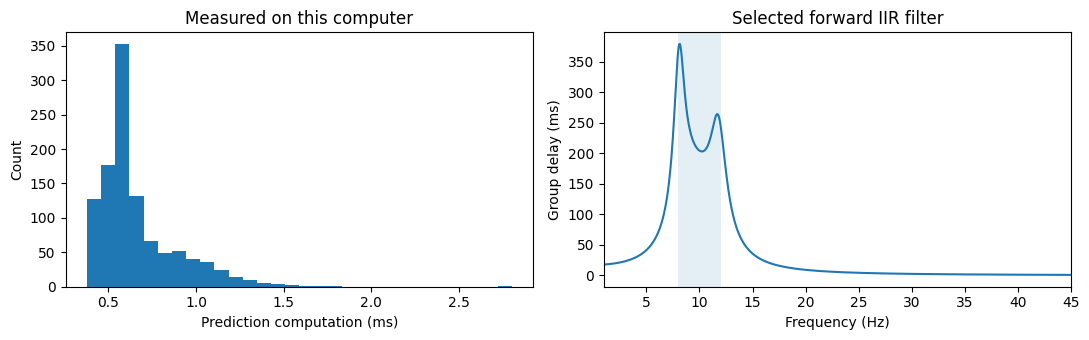

Group delay at 10 / 20 Hz (ms): [204.6   9.2]


In [ ]:
from scipy.signal import freqz_sos

freq, response = freqz_sos(sos, worN=np.linspace(.5, 60, 2000), fs=fs)
group_delay_ms = -np.gradient(np.unwrap(np.angle(response)), 2*np.pi*freq)*1000
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].hist(online.predict_ms, bins=30)
axes[0].set(xlabel="Prediction computation (ms)", ylabel="Count", title="Measured on this computer")
axes[1].plot(freq, group_delay_ms)
axes[1].axvspan(*BAND, alpha=.12)
axes[1].set(xlim=(1, 45), xlabel="Frequency (Hz)", ylabel="Group delay (ms)",
            title="Selected forward IIR filter")
plt.tight_layout(); plt.show()
print("Group delay at 10 / 20 Hz (ms):", np.interp([10, 20], freq, group_delay_ms).round(1))

For each state change, measure the time until three consecutive correct updates. A result can be early if the model was already predicting the upcoming state.

In [32]:
# A task-level latency: first three consecutive correct updates after each switch.
# This can be optimistic if the model was already predicting the upcoming state.
transitions = []
for row in intervals[intervals.split == "test"].itertuples():
    segment = online[(online.time >= row.start) & (online.time < min(row.end, row.start + 5))]
    correct = ((segment.p_watch.to_numpy() >= .5) == row.label)
    hits = np.flatnonzero(np.convolve(correct.astype(int), np.ones(3, dtype=int), mode="valid") == 3)
    delay = segment.time.iloc[hits[0] + 2] - row.start if len(hits) else np.nan
    transitions.append((CLASS_NAMES[row.label], delay))
transitions = pd.DataFrame(transitions, columns=["new_state", "three_correct_updates_s"])
display(transitions.groupby("new_state").agg(
    median_s=("three_correct_updates_s", "median"),
    no_success_within_5s=("three_correct_updates_s", lambda s: s.isna().sum()),
    transitions=("three_correct_updates_s", "size")))

,median_s,no_success_within_5s,transitions
new_state,,,
Rating,2.261,0,11
Watching,2.638,0,11


## 9 · Watch live decoding for 60 seconds

This is a **new EEG replay of the first test minute**, using the same frozen model. It starts from the saved calibration filter state, then advances at recording speed. It does not play the original stimulus video. The default Matplotlib colors show the true task for the audience; the decoder sees EEG only.

This cell uses a regular notebook PNG output refreshed after every prediction.

The final frame stays visible in the notebook. Interrupt the cell to stop early; the replay closes its file in `finally`. Change `LIVE_SECONDS` or `speed` to change the demonstration duration or playback speed. These display settings do not change the full-test metrics above.

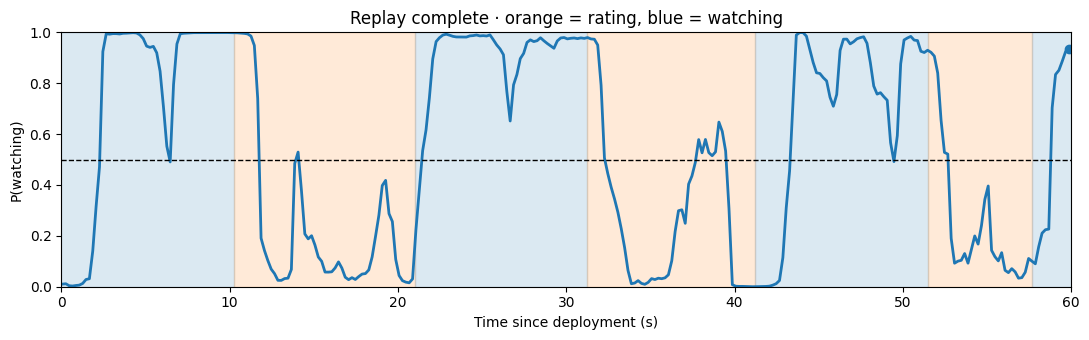

Displayed 300 predictions.


In [33]:
LIVE_SECONDS = 60
fig, ax = plt.subplots(figsize=(11, 3.5))
for row in intervals.itertuples():
    if row.end > cut_s and row.start < cut_s + LIVE_SECONDS:
        ax.axvspan(row.start-cut_s, row.end-cut_s, color=COLORS[row.label], alpha=.16)
line, = ax.plot([], [], lw=2)
point, = ax.plot([], [], "o", color=line.get_color())
ax.axhline(.5, color="black", ls="--", lw=1)
ax.set(xlim=(0, LIVE_SECONDS), ylim=(0, 1), xlabel="Time since deployment (s)",
       ylabel="P(watching)", title="Waiting for the first test chunk…")
plt.tight_layout()
# Update a regular PNG output: no ipympl widget renderer is needed.
plot_display = display(fig, display_id=True)
plt.close(fig)  # Prevent a duplicate automatic figure at the end of the cell.
live_times, live_probabilities = [], []
def update_live(t, p):
    live_times.append(t-cut_s); live_probabilities.append(p)
    line.set_data(live_times, live_probabilities)
    point.set_data([t-cut_s], [p])
    ax.set_title(f"Decoded: {CLASS_NAMES[int(p >= .5)]}  |  P(watching)={p:.2f}  |  2 s history")
    plot_display.update(fig)

live = await replay(stop_s=min(cut_s + LIVE_SECONDS, end_s), speed=1, update=update_live)
ax.set_title("Replay complete · orange = rating, blue = watching")
plot_display.update(fig)
print(f"Displayed {len(live)} predictions.")

## Takeaways and small exercises

- A causal filter remembers the past. An online decoder must use the same reference, filter, sample rate, window length and channel order as training.
- For this behavioral task, ocular/muscle artifacts explains successful decoding performance. When participants start the rating activity, they move, leading to less clean EEG signals. The decoding may have very little to do with real brain activity.
- Try a shorter window or fewer electrodes **using calibration folds**. Keep the final test reserved for a new comparison declared in advance; repeated tuning against it makes it a development set.
- Compare later sessions only after saving this pipeline and freezing its settings. This notebook establishes within-session, single-subject performance. How does it perform for other subjects?

### References

- [MNE CSP API and theory references](https://mne.tools/stable/generated/mne.decoding.CSP.html): spatial filters and log-power features.
- [SciPy sosfilt](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.sosfilt.html): filtering with explicit state.
- [scikit-learn TimeSeriesSplit](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.TimeSeriesSplit.html): expanding training sets; here it is applied to complete cycles, not individual windows.